# Data exploration

This notebook explores the Gallstone dataset from the UCI Machine Learning Repository and prepares it for modeling. It covers:

1. a first look at the data (size, types, missing values, duplicates),
2. the distribution of the target variable, overall and by sex,
3. the detection and handling of implausible values,
4. the identification of skewed features,
5. the removal of highly correlated features.

*References: Irfan Esen, Hilal Arslan, Selin Akt¨urk, Mervenur
G¨uls¸en, Nimet K¨ultekin, and O˘guzhan ¨Ozdemir. Gall-
stone. UCI Machine Learning Repository, 2024. DOI:
https://doi.org/10.1097/md.0000000000037258*

## Dependencies import

We import the libraries used in this notebook and print their versions, so the results can be reproduced with the same environment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")

NumPy: 2.5.4
pandas: 3.1.1


## Initial Data Review

We load the dataset and check its size and the data type of each column. Integer columns are binary indicators (e.g. diabetes), ordinal grades (e.g. hepatic fat accumulation) or whole-number measurements; float columns are continuous measurements.

In [2]:
# Since the dataset file is saved in the Strict Open XML Spreadsheet format, we
# have to use `calamine` to read it
df = pd.read_excel("dataset/dataset-uci.xlsx", engine="calamine")

# Shape of dataset; data types; feature overview; missing values; duplicates; etc.
rows = len(df)
print(f"Number of rows: {rows}")
# how many columns we have of data
columns = len(df.columns)
print(f"Number of columns: {columns}")

print(f"Dataset shape: {df.shape}")
print(f"Dataset datatypes:\n{df.dtypes}")

Number of rows: 319
Number of columns: 39
Dataset shape: (319, 39)
Dataset datatypes:
Gallstone Status                                    int64
Age                                                 int64
Gender                                              int64
Comorbidity                                         int64
Coronary Artery Disease (CAD)                       int64
Hypothyroidism                                      int64
Hyperlipidemia                                      int64
Diabetes Mellitus (DM)                              int64
Height                                              int64
Weight                                            float64
Body Mass Index (BMI)                             float64
Total Body Water (TBW)                            float64
Extracellular Water (ECW)                         float64
Intracellular Water (ICW)                         float64
Extracellular Fluid/Total Body Water (ECF/TBW)    float64
Total Body Fat Ratio (TBFR) (%)             

## Cleaning

We check the data for missing values and duplicated records. Both counts are zero, so no imputation or deduplication is needed for the original data.

In [3]:
print(f"# null values for each feature:\n{df.isnull().sum()}")
print(f"# null values: {df.isnull().sum().sum()}")

print(f"# duplicated values: {df.duplicated().sum()}")

# null values for each feature:
Gallstone Status                                  0
Age                                               0
Gender                                            0
Comorbidity                                       0
Coronary Artery Disease (CAD)                     0
Hypothyroidism                                    0
Hyperlipidemia                                    0
Diabetes Mellitus (DM)                            0
Height                                            0
Weight                                            0
Body Mass Index (BMI)                             0
Total Body Water (TBW)                            0
Extracellular Water (ECW)                         0
Intracellular Water (ICW)                         0
Extracellular Fluid/Total Body Water (ECF/TBW)    0
Total Body Fat Ratio (TBFR) (%)                   0
Lean Mass (LM) (%)                                0
Body Protein Content (Protein) (%)                0
Visceral Fat Rating (VFR)       

## Visualization

We separate the target variable (`Gallstone Status`) from the features.

In [4]:
y = df["Gallstone Status"]
X = df.drop(columns="Gallstone Status")

### Target distribution

First, we look at how many patients have and do not have gallstones. A balanced dataset means that accuracy is a meaningful metric and that no resampling is needed.

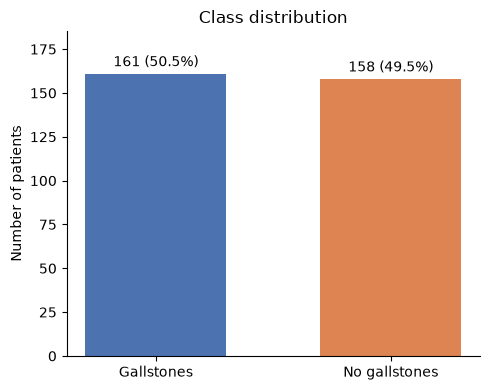

In [5]:
counts = y.value_counts().sort_index()

names = {0: "Gallstones", 1: "No gallstones"}   # original coding: 0 = present, 1 = absent

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar([names[i] for i in counts.index], counts.values,
              color=["#4C72B0", "#DD8452"], width=0.6)

ax.bar_label(bars, labels=[f"{v} ({v / counts.sum():.1%})" for v in counts.values],
             padding=3)
ax.set_ylabel("Number of patients")
ax.set_title("Class distribution")
ax.set_ylim(0, counts.max() * 1.15)          # room for the labels above the bars
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

The classes are nearly balanced (about 50/50), so no resampling is needed.

### Target distribution by sex

Next, we split the patients by sex. The percentages on the bars are computed **within each sex**, so they show the share of men and of women with and without gallstones. This tells us whether sex is associated with gallstone status, and why it may appear as a relevant feature in the models later on.

Gallstone Status  Gallstones  No gallstones
Gender                                     
Male                      94             68
Female                    67             90


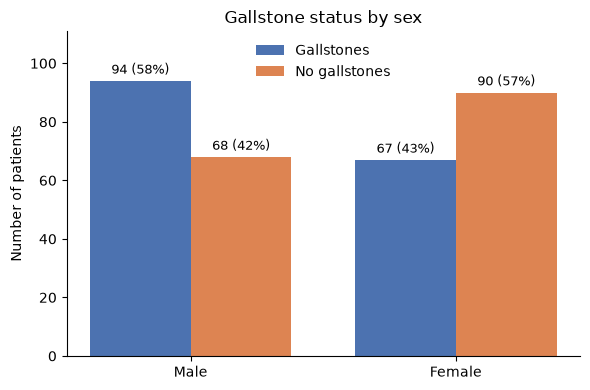

In [6]:
sex = X["Gender"].map({0: "Male", 1: "Female"})
status = y.map(names)          # same `names` mapping as before

ct = pd.crosstab(sex, status).loc[["Male", "Female"], ["Gallstones", "No gallstones"]]
print(ct)

fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(ct.index))
w = 0.38

for i, (col, color) in enumerate(zip(ct.columns, ["#4C72B0", "#DD8452"])):
    vals = ct[col].values
    share = vals / ct.sum(axis=1).values        # share within each sex
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=col, color=color)
    ax.bar_label(bars, labels=[f"{v} ({s:.0%})" for v, s in zip(vals, share)],
                 padding=3, fontsize=9)

ax.set_xticks(x, ct.index)
ax.set_ylabel("Number of patients")
ax.set_title("Gallstone status by sex")
ax.set_ylim(0, ct.values.max() * 1.18)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

The distribution of gallstone status differs between the sexes: 58.0% of men have gallstones, compared with 43% of women. Sex may therefore be a relevant feature for the models’ predictions, which we evaluate later in the feature importance analysis.

## Preprocessing

### Outliers handling

We look for implausible values with the **z-score**: the number of standard deviations a value lies from the mean of its feature,

$$z = \frac{x - \mu}{\sigma}.$$

We use a deliberately high threshold, $|z| > 10$, so that only extreme values are flagged. These are much more likely to be data-entry errors than natural variation between patients. Each flagged value is then checked individually for clinical plausibility and for consistency with other measurements of the same patient.

In [7]:
# Outlier
v_max =  X.max()
v_mean = X.mean()
v_min =  X.min()
v_std =  X.std()

z = (X - v_mean) / v_std
outliers = z.abs() > 10

outliers.sum()               # number of outliers per column

Age                                               0
Gender                                            0
Comorbidity                                       0
Coronary Artery Disease (CAD)                     0
Hypothyroidism                                    0
Hyperlipidemia                                    0
Diabetes Mellitus (DM)                            0
Height                                            0
Weight                                            0
Body Mass Index (BMI)                             0
Total Body Water (TBW)                            0
Extracellular Water (ECW)                         0
Intracellular Water (ICW)                         0
Extracellular Fluid/Total Body Water (ECF/TBW)    0
Total Body Fat Ratio (TBFR) (%)                   0
Lean Mass (LM) (%)                                0
Body Protein Content (Protein) (%)                0
Visceral Fat Rating (VFR)                         0
Bone Mass (BM)                                    0
Muscle Mass 

The table below shows each flagged value with the mean, standard deviation and z-score of its feature.

In [8]:
result = pd.DataFrame({
    "value": X[outliers].stack().dropna(),
    "z": z[outliers].stack().dropna(),
})

feature = result.index.get_level_values(1)
result["mean"] = v_mean[feature].values
result["std"] = v_std[feature].values

result = result[["value", "mean", "std", "z"]].rename_axis(["Record", "Feature"])
result.round(2)

value    mean     std      z
Record Feature                                                      
40     Glucose                          575.0  108.69   44.85  10.40
239    Obesity (%)                     1954.0   35.85  109.80  17.47
278    Aspartat Aminotransferaz (AST)   195.0   21.68   16.70  10.38
       Alanin Aminotransferaz (ALT)     372.0   26.86   27.88  12.38
318    High Density Lipoprotein (HDL)   273.0   49.48   17.72  12.62

**Record 40:** a glucose level of 575 mg/dl is implausibly high for a patient who is not diabetic (`Diabetes Mellitus (DM) = 0`). Since the correct value cannot be recovered, we drop the whole record.

*Reference: Guido Freckmann, Sven Hagenlocher, Annette Baum-
stark, Nina Jendrike, Ralph C. Gillen, Katja R¨ossner, and
Cornelia Haug. Continuous glucose profiles in healthy
subjects under everyday life conditions and after dif-
ferent meals. Journal of Diabetes Science and Tech-
nology, 1(5):695–703, September 2007. doi: 10.1177/
193229680700100513.*

In [9]:
X.loc[40, "Diabetes Mellitus (DM)"]

np.int64(0)

In [10]:
X = X.drop(40)
y = y.drop(40)

**Record 239:** an obesity percentage of 1954% is physically impossible. The patient's height, weight and BMI are consistent with each other (65.9 / 1.50² ≈ 29.3), and a value of 19.54% matches the BMI-based definition of obesity percentage. We therefore treat it as a missing decimal point and correct it.

In [11]:
X.loc[239, ["Height", "Weight", "Body Mass Index (BMI)"]]

Height                   150.0
Weight                    65.9
Body Mass Index (BMI)     29.3
Name: 239, dtype: float64

In [12]:
X.loc[239, "Obesity (%)"] = 19.54

**Record 318:** an HDL of 273 mg/dl is not only extreme but also inconsistent: total cholesterol includes LDL and HDL, yet here LDL + HDL = 155 + 273 = 428 mg/dl, which exceeds the total cholesterol of 296 mg/dl. The value is certainly an error, so we drop the record.

*Reference: William T. Friedewald, Robert I. Levy, and Donald S.
Fredrickson. Estimation of the concentration of low-
density lipoprotein cholesterol in plasma, without use of
the preparative ultracentrifuge. Clinical Chemistry, 18(6):
499–502, 1972. doi: 10.1093/clinchem/18.6.499.n*

In [13]:
X.loc[318, ["Total Cholesterol (TC)", "Low Density Lipoprotein (LDL)", "High Density Lipoprotein (HDL)"]]

Total Cholesterol (TC)            296.0
Low Density Lipoprotein (LDL)     155.0
High Density Lipoprotein (HDL)    273.0
Name: 318, dtype: float64

In [14]:
X = X.drop(318)
y = y.drop(318)

## Feature Selection

### Highly correlated features

Many bioimpedance features measure closely related aspects of body composition. Features that are almost perfectly correlated carry nearly the same information, and in a linear model they make the coefficients unstable and hard to interpret. We compute the absolute Pearson correlation between every pair of features and list the pairs above 0.9.

In [15]:
# Highly correlated features
corr = X.corr().abs()
upper = corr.where(np.triu(
    np.ones(corr.shape, dtype=bool),
    k=1
))  # upper triangle only

pairs = upper.stack()
high = pairs[pairs > 0.9]
high.sort_values(key=np.abs, ascending=False)

Total Body Fat Ratio (TBFR) (%)  Lean Mass (LM) (%)           0.994034
Total Body Water (TBW)           Muscle Mass (MM)             0.928283
Body Mass Index (BMI)            Obesity (%)                  0.917529
Total Body Water (TBW)           Extracellular Water (ECW)    0.904031
Intracellular Water (ICW)        Muscle Mass (MM)             0.903599
Body Mass Index (BMI)            Total Fat Content (TFC)      0.902578
dtype: float64

The heatmap gives an overview of all pairwise correlations. Dark cells off the diagonal mark redundant features; most of them are among the body composition measurements.

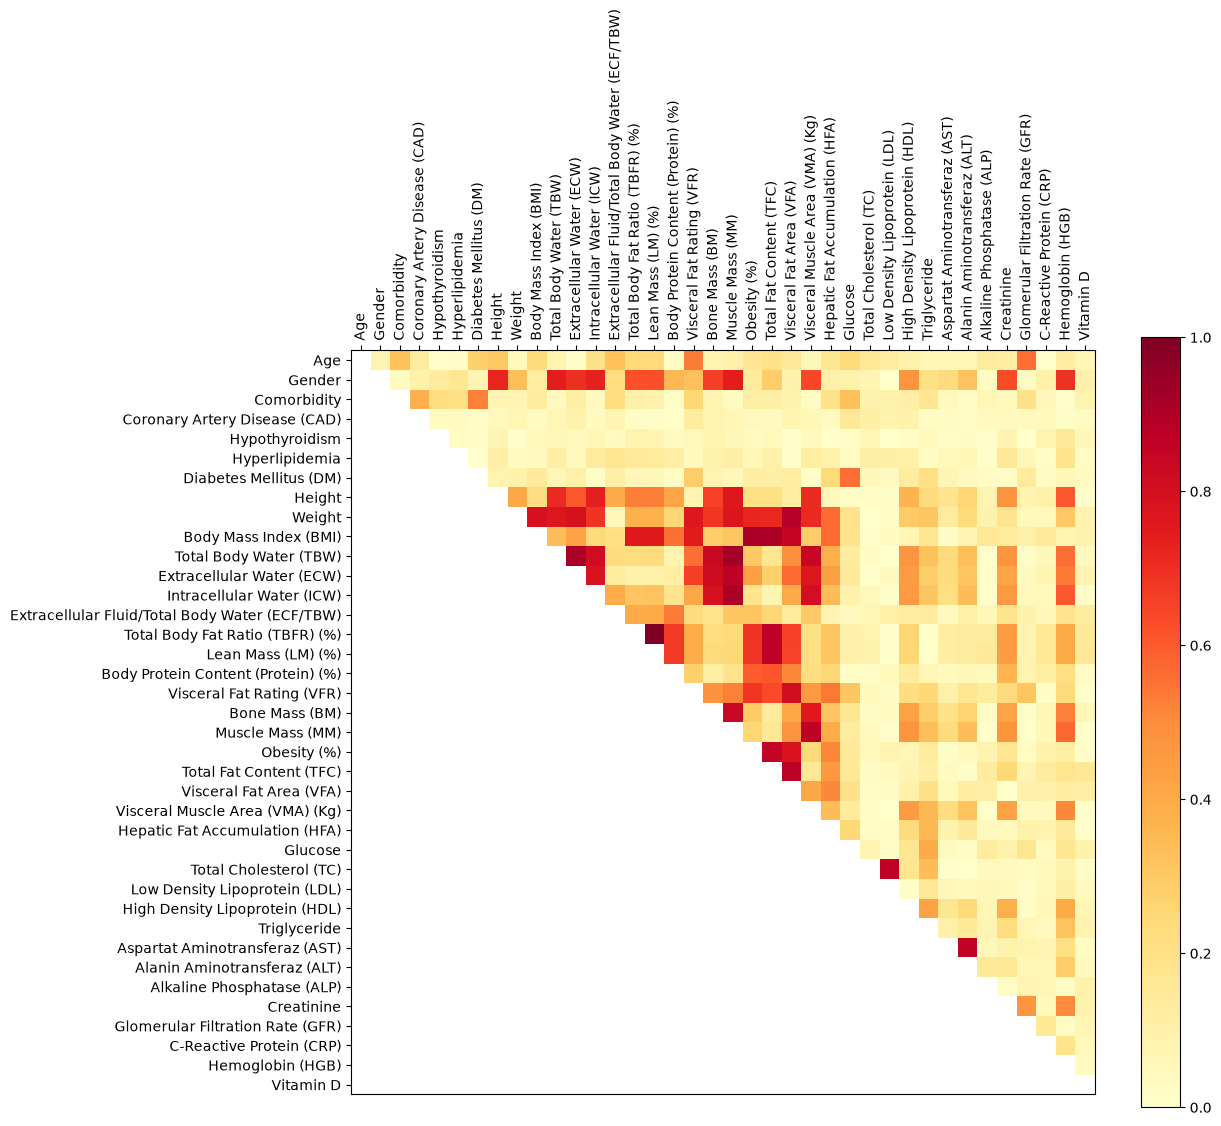

In [ ]:
plt.figure(figsize=(12, 10))
plt.imshow(corr, cmap="YlOrRd", vmin=0, vmax=1)
plt.colorbar()
plt.xticks(range(len(X.columns)), X.columns, rotation=90)
plt.yticks(range(len(X.columns)), X.columns)
plt.tight_layout()
plt.show()

We remove redundant features with a simple greedy rule: the columns are processed in their original order, and each one is kept only if its correlation with every column already kept is at most 0.9.

Compared with dropping one feature from every listed pair, this removes the minimum number of features: if A correlates with B and B with C, but A and C are not strongly related, only B is dropped. The rule does not use the target, so it introduces no information leakage into the later model evaluation.

In [17]:
keep = []
for c in X.columns:
    if not (corr.loc[c, keep] > 0.9).any():
        keep.append(c)

dropped = [c for c in X.columns if c not in keep]
print(f"Dropped {len(dropped)}:", dropped)

X = X[keep]

Dropped 5: ['Extracellular Water (ECW)', 'Lean Mass (LM) (%)', 'Muscle Mass (MM)', 'Obesity (%)', 'Total Fat Content (TFC)']


## Skewed features

Some models assumes that each feature affects the outcome linearly. Strongly **right-skewed** features (most patients in a narrow range, a few with much higher values) fit this assumption poorly: the few extreme patients dominate the fitted weights, and the typical patients get squeezed together after standardization.

We compute the sample skewness of every continuous feature (binary and ordinal features are excluded, since skewness is not meaningful for them). Features with a skewness above 1, a common rule of thumb for strong skewness, are candidates for a $\log(1 + x)$ transformation. The table compares the skewness before and after the transformation.

In [18]:
# Continuous features only (binary and ordinal ones have ≤ 5 distinct values)
cont = [c for c in X.columns if X[c].nunique() > 5]

skew = X[cont].skew()
skewed = skew[skew > 1].index.tolist()             # strongly right-skewed
skewed = [c for c in skewed if (X[c] >= 0).all()]  # log1p needs x > -1

skew_table = pd.DataFrame({
    "Skewness": skew[skewed],
    "After log": np.log1p(X[skewed]).skew(),
}).sort_values("Skewness", ascending=False).round(2)

skew_table
#print(skew_table.to_latex())

,Skewness,After log
Alanin Aminotransferaz (ALT),7.36,0.92
Aspartat Aminotransferaz (AST),6.98,1.74
C-Reactive Protein (CRP),5.39,1.68
Glucose,4.56,2.87
Triglyceride,2.80,-0.63
Visceral Fat Area (VFA),1.05,-0.76


## Summary

- The dataset contains 319 patients and 38 features, with no missing values or duplicates and nearly balanced classes.
- Two records with implausible values (40 and 318) were removed, and one decimal error (record 239) was corrected.
- Seven continuous features are strongly right-skewed and are candidates for a log transformation in the linear models.
- Five redundant body composition features were removed because of correlations above 0.9.